In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('credit_risk_dataset.csv')

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.isnull().mean() * 100

person_age                    0.000000
person_income                 0.000000
person_home_ownership         0.000000
person_emp_length             2.747000
loan_intent                   0.000000
loan_grade                    0.000000
loan_amnt                     0.000000
loan_int_rate                 9.563856
loan_status                   0.000000
loan_percent_income           0.000000
cb_person_default_on_file     0.000000
cb_person_cred_hist_length    0.000000
dtype: float64

In [5]:
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].mean)
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].mean)


In [6]:
from catboost import CatBoostRegressor
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [8]:
from sklearn.model_selection import train_test_split
numeric_cols = [
    'person_age', 'person_income', 'person_emp_length', 
    'loan_amnt', 'loan_int_rate', 'loan_percent_income', 
    'cb_person_cred_hist_length'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')


In [9]:
X = df.drop(columns = 'loan_status')
y = df['loan_status']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import classification_report, roc_auc_score

cat_features = [
    'person_home_ownership', 
    'loan_intent', 
    'loan_grade', 
    'cb_person_default_on_file'
]

for col in cat_features:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

model = CatBoostClassifier(
    iterations=500,          # Количество деревьев (эпох обучения)
    learning_rate=0.05,      # Скорость обучения
    depth=6,                 # Глубина деревьев
    loss_function='Logloss', # Функция потерь для бинарной классификации (0 или 1)
    eval_metric='AUC',       # Метрика для оценки качества на валидации
    random_seed=42,          # Воспроизводимость результатов
    verbose=100              # Выводить логи обучения каждые 100 итераций
)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50
)

0:	test: 0.8607612	best: 0.8607612 (0)	total: 70ms	remaining: 34.9s
100:	test: 0.9274264	best: 0.9274264 (100)	total: 574ms	remaining: 2.27s
200:	test: 0.9338472	best: 0.9338472 (200)	total: 1.09s	remaining: 1.63s
300:	test: 0.9391055	best: 0.9391055 (300)	total: 1.64s	remaining: 1.08s
400:	test: 0.9425817	best: 0.9426084 (399)	total: 2.18s	remaining: 539ms
499:	test: 0.9450646	best: 0.9450678 (498)	total: 2.71s	remaining: 0us

bestTest = 0.9450677631
bestIteration = 498

Shrink model to first 499 iterations.


CatBoostClassifier(depth=6, eval_metric='AUC', iterations=500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [13]:
import pandas as pd
from catboost import CatBoostClassifier

X_full = df.drop(columns=['loan_status'])
y_full = df['loan_status']

cat_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
for col in cat_features:
    X_full[col] = X_full[col].astype(str)

final_model = CatBoostClassifier(
    iterations=500, 
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    random_seed=42,
    verbose=100 
)

final_model.fit(
    X_full, y_full,
    cat_features=cat_features
)


0:	learn: 0.6463822	total: 10.1ms	remaining: 5.06s
100:	learn: 0.2078190	total: 536ms	remaining: 2.12s
200:	learn: 0.1954556	total: 1.07s	remaining: 1.59s
300:	learn: 0.1847665	total: 1.65s	remaining: 1.09s
400:	learn: 0.1771236	total: 2.22s	remaining: 548ms
499:	learn: 0.1704600	total: 2.79s	remaining: 0us


CatBoostClassifier(depth=6, iterations=500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

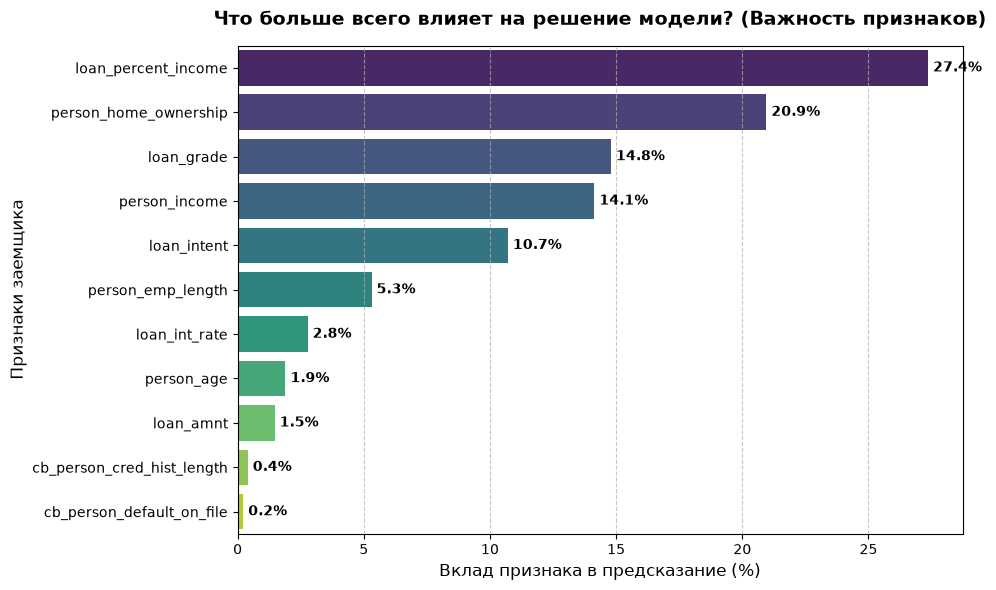

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Извлекаем важность признаков
importances = final_model.get_feature_importance()
features = X_full.columns

# 2. Создаем DataFrame и сортируем
df_importance = pd.DataFrame({
    'Признак': features,
    'Важность (%)': importances
}).sort_values(by='Важность (%)', ascending=False)

# 3. Строим график (теперь без предупреждений)
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Важность (%)', 
    y='Признак', 
    data=df_importance, 
    hue='Признак',       # Назначаем hue для правильного окрашивания по строкам
    legend=False,        # Отключаем ненужную легенду
    palette='viridis'
)

# Настройки оформления
plt.title('Что больше всего влияет на решение модели? (Важность признаков)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Вклад признака в предсказание (%)', fontsize=12)
plt.ylabel('Признаки заемщика', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Добавляем текстовые подписи к столбцам
for index, value in enumerate(df_importance['Важность (%)']):
    plt.text(value + 0.2, index, f'{value:.1f}%', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


In [16]:
final_model.save_model('credit_model.cbm')